# S3 · Classroom relational structure

Each classroom is a small closed group in which we observe several
networks at once. This notebook describes the three nomination networks
used in the analysis and draws them for a few classrooms. Code:
`code/si/S3_relational_structure.R`.

In [ ]:
here::i_am("notebooks/si/S3_relational_structure.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(igraph)
library(ggraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

question_names <- c(
  nom_q1 = "Most like to hang out (Q1)",  nom_q2 = "Least like to hang out (Q2)",
  nom_q3 = "Best friends (Q3)",            nom_q4 = "Most popular (Q4)",
  nom_q5 = "Not popular (Q5)",             nom_q6 = "Start fights (Q6)",
  nom_q7 = "Make fun of others (Q7)",      nom_q8 = "Kind to others (Q8)",
  nom_q9 = "Cooperate (Q9)"
)

## Network statistics, classroom by classroom (Table S6)

Table S6 computes the number of ties, density, nominations received,
reciprocity (the share of ties that are returned), and isolates by
classroom and question. The preview shows classroom 1. The R script
exports the results for all classrooms.

In [ ]:
# For one classroom and one question, the directed nomination network and
# its statistics. Ties are nominations i -> j; "no tie" is an observed
# non-nomination, not missing data.

network_statistics <- function(this_class, question) {
  class_dyads <- dyads %>% filter(class_id == this_class)
  n_children <- n_distinct(class_dyads$sender_id)
  nominations <- class_dyads %>% filter(.data[[question]] == 1)

  received <- class_dyads %>% group_by(id = receiver_id) %>% summarise(k_in = sum(.data[[question]]))
  sent     <- class_dyads %>% group_by(id = sender_id)   %>% summarise(k_out = sum(.data[[question]]))
  degrees  <- full_join(received, sent, by = "id")

  # reciprocity: share of ties whose reverse tie also exists
  reciprocated <- nominations %>%
    semi_join(nominations, by = c("sender_id" = "receiver_id", "receiver_id" = "sender_id"))

  tibble(class_id      = this_class,
         question      = question,
         n             = n_children,
         ties          = nrow(nominations),
         density       = nrow(nominations) / (n_children * (n_children - 1)),
         mean_received = mean(degrees$k_in),
         min_received  = min(degrees$k_in),
         max_received  = max(degrees$k_in),
         zero_received = sum(degrees$k_in == 0),
         reciprocity   = nrow(reciprocated) / nrow(nominations),
         isolates      = sum(degrees$k_in == 0 & degrees$k_out == 0))
}

table_s6 <- expand_grid(this_class = sort(unique(dyads$class_id)),
                        question   = c("nom_q3", "nom_q4", "nom_q5")) %>%
  pmap_dfr(network_statistics) %>%
  left_join(students %>% distinct(class_id, school_id), by = "class_id") %>%
  mutate(network = question_names[question], .after = n)

table_s6 %>% filter(class_id == 1)

class_id,question,n,network,ties,density,mean_received,min_received,max_received,zero_received,reciprocity,isolates,school_id
1,nom_q3,33,Best friends (Q3),114,0.1079545,3.454546,0,9,1,0.4736842,0,1
1,nom_q4,33,Most popular (Q4),98,0.0928030,2.969697,0,16,6,0.1632653,0,1
1,nom_q5,33,Not popular (Q5),78,0.0738636,2.363636,0,14,6,0.0769231,0,1


## Table S5. Summary over the 45 classrooms

Median and range of each statistic across classrooms.

In [ ]:
# Table S5: median and range over the 45 classrooms
median_range <- function(x, digits = 2) {
  paste0(format(round(median(x), digits), nsmall = digits),
         " [", format(round(min(x), digits), nsmall = digits), "-",
         format(round(max(x), digits), nsmall = digits), "]")
}

table_s5 <- table_s6 %>%
  group_by(network) %>%
  summarise(`Classroom size`             = median_range(n, 0),
            `Directed ties`              = median_range(ties, 0),
            Density                      = median_range(density),
            `Mean nominations received`  = median_range(mean_received),
            `Max nominations received`   = median_range(max_received, 0),
            Reciprocity                  = median_range(reciprocity),
            `Students with zero received` = median_range(zero_received, 0),
            Isolates                     = median_range(isolates, 0)) %>%
  pivot_longer(-network, names_to = "statistic") %>%
  pivot_wider(names_from = network, values_from = value)

In [ ]:
knitr::kable(table_s5)

statistic,Best friends (Q3),Most popular (Q4),Not popular (Q5)
Classroom size,18 [7-39],18 [7-39],18 [7-39]
Directed ties,52 [15-145],46 [12-130],41 [6-104]
Density,0.17 [0.10-0.36],0.14 [0.09-0.35],0.12 [0.07-0.29]
Mean nominations received,3.00 [1.87-4.00],2.52 [1.21-3.83],2.17 [0.60-3.09]
Max nominations received,8 [3-12],10 [3-22],7 [3-14]
Reciprocity,0.51 [0.32-0.70],0.21 [0.00-0.67],0.12 [0.00-0.50]
Students with zero received,2 [0-5],4 [1-12],3 [0-9]
Isolates,0 [0-2],0 [0-1],0 [0-4]


## Sociograms

The same layout is used for every layer of a classroom, so each child
keeps her position. Node size is nominations received (or tokens), and
the subtitle gives the share of ties between children of the same sex.

In [ ]:
# One sociogram: one classroom, one layer. Node size = nominations received
# (or tokens received/sent), fill = sex. The layout is fixed per classroom
# so the same child stays in the same place in every panel.

class_layout <- function(this_class, seed = 1) {
  class_dyads <- dyads %>% filter(class_id == this_class)
  links <- class_dyads %>%
    filter(nom_q3 == 1 | nom_q4 == 1 | nom_q5 == 1) %>%
    transmute(from = as.character(sender_id), to = as.character(receiver_id))
  nodes <- students %>% filter(class_id == this_class) %>%
    transmute(name = as.character(student_id), sex = if_else(female == 1, "Female", "Male"))
  set.seed(seed)
  xy <- layout_with_fr(graph_from_data_frame(links, vertices = nodes))
  nodes %>% mutate(x = xy[, 1], y = xy[, 2])
}

draw_sociogram <- function(this_class, layer, nodes, title = layer) {
  class_dyads <- dyads %>% filter(class_id == this_class) %>%
    mutate(from = as.character(sender_id), to = as.character(receiver_id))

  if (layer %in% c("tokens_sent", "tokens_received")) {
    links <- class_dyads %>% filter(tokens_sent > 0) %>% mutate(width = tokens_sent)
    size  <- class_dyads %>%
      group_by(name = if (layer == "tokens_sent") from else to) %>%
      summarise(size = sum(tokens_sent))
  } else {
    links <- class_dyads %>% filter(.data[[layer]] == 1) %>% mutate(width = 1)
    size  <- class_dyads %>% group_by(name = to) %>% summarise(size = sum(.data[[layer]]))
  }

  # share of ties between two children of the same sex
  sex_of <- setNames(nodes$sex, nodes$name)
  same_sex <- 100 * mean(sex_of[links$from] == sex_of[links$to])

  nodes <- nodes %>% left_join(size, by = "name")
  network <- graph_from_data_frame(links %>% select(from, to, width), vertices = nodes)

  ggraph(network, layout = "manual", x = V(network)$x, y = V(network)$y) +
    geom_edge_link(aes(width = width), color = "grey45", alpha = 0.6,
                   arrow = arrow(length = unit(1.5, "mm"), type = "closed"),
                   end_cap = circle(2.5, "mm")) +
    geom_node_point(aes(size = size, fill = sex), shape = 21, color = "grey20") +
    scale_edge_width(range = c(0.2, 1)) +
    scale_fill_manual(values = c(Female = color_female, Male = color_male)) +
    scale_size_continuous(range = c(1.5, 7)) +
    labs(title = title, subtitle = sprintf("%.0f%% same-sex ties", same_sex)) +
    theme_void(base_size = 8) +
    theme(legend.position = "none", plot.title = element_text(face = "bold"))
}

### Figure S2. All layers of classroom 20

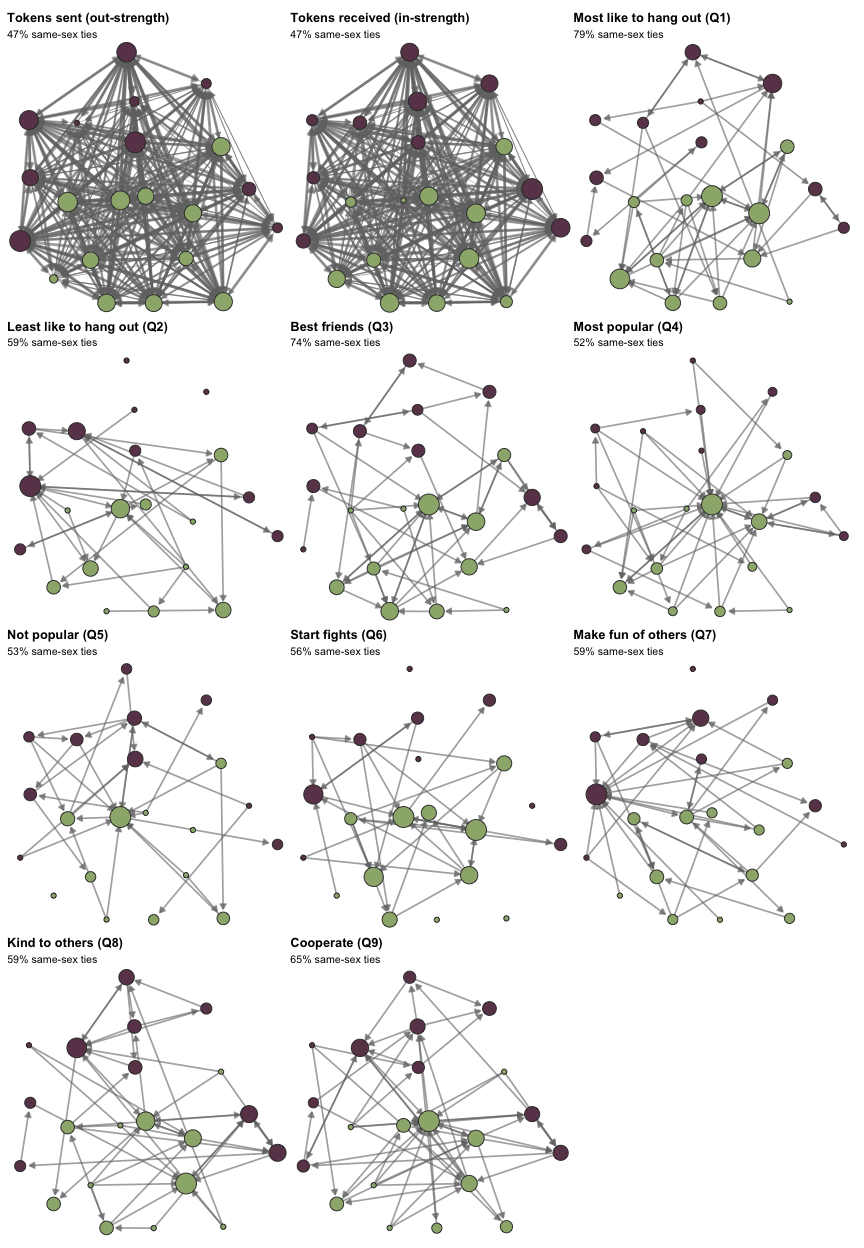

In [ ]:
# Figure S2: every layer of class 20
nodes_20 <- class_layout(20, seed = 20)
layers <- c("tokens_sent", "tokens_received", names(question_names))
layer_titles <- c("Tokens sent (out-strength)", "Tokens received (in-strength)", question_names)

figure_s2 <- map2(layers, layer_titles, ~ draw_sociogram(20, .x, nodes_20, .y)) %>%
  wrap_plots(ncol = 3)

figure_s2

### Figures S3–S5. Small, intermediate and large classrooms

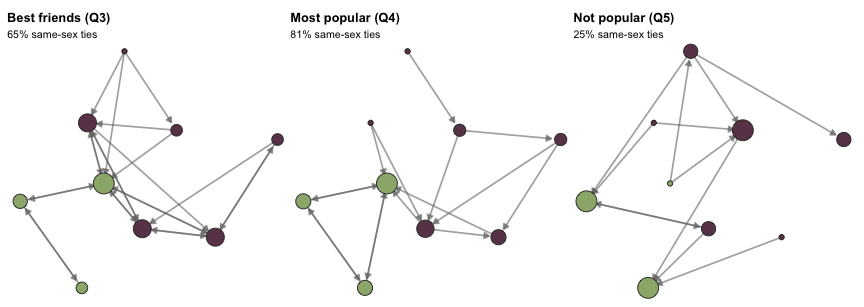

In [ ]:
# Figures S3-S5: the three focal questions for three classroom sizes
focal <- c(nom_q3 = "Best friends (Q3)", nom_q4 = "Most popular (Q4)", nom_q5 = "Not popular (Q5)")

three_layers <- function(this_class) {
  nodes <- class_layout(this_class, seed = this_class)
  map2(names(focal), focal, ~ draw_sociogram(this_class, .x, nodes, .y)) %>%
    wrap_plots(nrow = 1)
}

figure_s3 <- three_layers(16)   # small, 9 children
figure_s4 <- three_layers(40)   # intermediate, 18 children (all girls)
figure_s5 <- three_layers(1)    # large, 33 children

figure_s3

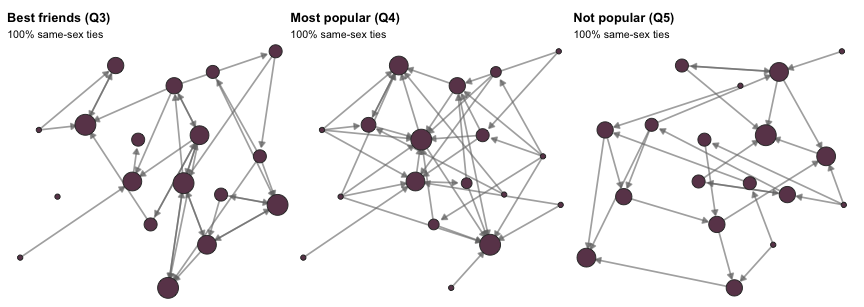

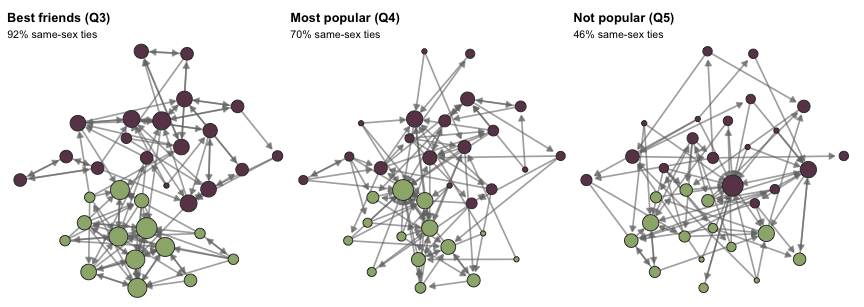

In [ ]:
figure_s4

In [ ]:
save_table(table_s5, "S3_table_s5_network_summary")
save_table(table_s6, "S3_table_s6_network_by_class")
save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}
save_si_figure(figure_s2, "S3_figure_s2_class20_layers", 9, 13)
save_si_figure(figure_s3, "S3_figure_s3_class16", 9, 3.2)
save_si_figure(figure_s4, "S3_figure_s4_class40", 9, 3.2)
save_si_figure(figure_s5, "S3_figure_s5_class1", 9, 3.2)